 **Aircraft Predictive Maintenance Remaining Useful Life (RUL) Prediction**


**What this project does?**

Jet engines do not fail without warning. Long before an engine actually breaks, its
internal sensors start drifting temperatures go up, pressures shift, efficiency
falls away. Predictive maintenance is the practice of reading those unusual readings and
estimating how much life a machine has left, so it can be serviced before it
fails rather than after, and saving time for the airlines.

This notebook uses NASA's C-MAPSS simulated turbofan dataset to answer two questions
about an engine, given only its sensor history:

1. **How many flight cycles does this engine have left?** (a regression problem,
   the answer is a number of  Remaining Useful Life for that engine)
2. **Is this engine about to fail soon?** (a classification problem, the answer is
   yes or no)

These are two different types of problems being solved with this model its important to understand that regression is completely different from the classification. The C-MAPSS has 4 datasets that have different operation conditions and fault modes For this project I only used the FD001 dataset, its the basic one and its easier for this model, its the cleanest dataset out of all of them with only one operating condition and a signle fault mode. There are 3 different datasets within the FD001 file. First is train_FD001, every engine is run to failure. Second is test_FD001, where the engine is cut off at a random point. Lastly, RUL_FD001 which shows us how many true cycles where left at the moment the recording stopped. The idea is to recognize the degradation pattern and predict how much life is left for every engine.

I'll be using a couple of tools and core libraries that are supposed to be downloaded in the first cells, but for the sake of explaining why each library is used I'll be importing it once its needed.


**Installing kagglehub**

This step is important in order to get the dataset of Kaggle, without having to download it manually on my device. If this model is to be published you would have to download the data and then unzip the files in order to access the data


In [1]:
pip install kagglehub


**Loading the dataset into the collab notebook**




In [2]:
import kagglehub

# The dataset handle for 'NASA CMaps' is 'behrad3d/nasa-cmaps'
dataset_handle = 'behrad3d/nasa-cmaps'

# Download the dataset
dataset_path = kagglehub.dataset_download(dataset_handle)
print(f"Dataset downloaded to: {dataset_path}")

Using Colab cache for faster access to the 'nasa-cmaps' dataset.
Dataset downloaded to: /kaggle/input/nasa-cmaps


After downloading the dataset into google collab now I'm loading the file that I will be using which is only the FD001 for this model. I'm also importing pandas, which is a tool used to clean your dataset and turn it into a table.

Loading the FD001 training data, it has a 100 train trajectories and a 100 test cycles.

Conditions: 1 (Sea level)
Faults: 1 (HPC Degradation)

In [3]:
# I need pandas and numpy for the data set and for training the model
# Random state is set at 42 which is the default for a lot of data science projects
import pandas as pd
import numpy as np
RANDOM_STATE=42
np.random.seed(RANDOM_STATE)

# Define column names based on the dataset description, and there are 21 sensors.
index_names = ['engine', 'cycle']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = [f'sensor_{i}' for i in range(1, 22)]

# Combine all names into a single list
col_names = index_names + setting_names + sensor_names

# Load the training data into pandas, this line of code is for pandas to read the dataset
# File instructions indicate that there are white spaces between the values and no headers
# The result table is saved in train,test, and RUL each for its own file
train = pd.read_csv(f'{dataset_path}/CMaps/train_FD001.txt', sep=r'\s+', header=None, names=col_names)
test=pd.read_csv(f'{dataset_path}/CMaps/test_FD001.txt', sep=r'\s+', header=None, names=col_names)
RUL=pd.read_csv(f'{dataset_path}/CMaps/RUL_FD001.txt', sep=r'\s+', header=None, names=['RUL'])

# Display the head of the DataFrame to confirm that the data has been loaded correctly for each file
print("Training data:")
display(train.head())
print("\nTesting data:")
display(test.head())
print("\nRUL data:")
display(RUL.head())

# Show how many engines for the training dataset and for the testing dataset
print("Training engines:", train['engine'].nunique())
print("Test engines:", test['engine'].nunique())

# Every engine training cycle and see where it failed
print("Training lifespan: ")
train_lifespan=train.groupby('engine')['cycle'].max()
display(train_lifespan)

# Every engine and where it was randomly stopped
print("\nTest length: ")
test_length=test.groupby('engine')['cycle'].max()
display(test_length)


# Desrcibe is a useful pandas tool to show important stats about each dataset
print("\nTraining stats:")
display(train.describe())
print("\nTesting stats:")
display(test.describe())
print("\nRUL stats:")
display(RUL.describe())

# Finding the average life cycle for an engine using the training dataset
avg_train=train.groupby('engine')['cycle'].max().mean()
print("Average life cycle: ",avg_train)
# Finding minimum life cycle
min_train=train.groupby('engine')['cycle'].max().min()
print("Minimum life cycle: ",min_train)
# Finding maximum life cycle
max_train=train.groupby('engine')['cycle'].max().max()
print("Maximum life cycle: ",max_train)


Training data:


,engine,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044



Testing data:


,engine,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130



RUL data:


...


Testing stats:


,engine,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,13096.000000,13096.000000,13096.000000,13096.000000,13096.0,1.309600e+04,13096.000000,13096.000000,13096.000000,1.309600e+04,...,13096.000000,13096.000000,13096.000000,13096.000000,1.309600e+04,13096.000000,13096.0,13096.0,13096.000000,13096.000000
mean,51.543907,76.836515,-0.000011,0.000004,100.0,5.186700e+02,642.475088,1588.099204,1404.735362,1.462000e+01,...,521.747724,2388.071025,8138.947817,8.425844,3.000000e-02,392.571625,2388.0,100.0,38.892502,23.335743
std,28.289423,53.057749,0.002203,0.000294,0.0,6.014263e-11,0.400899,5.003274,6.688309,2.671743e-12,...,0.559627,0.056934,10.188605,0.029009,8.823140e-15,1.233577,0.0,0.0,0.141681,0.084120
min,1.000000,1.000000,-0.008200,-0.000600,100.0,5.186700e+02,641.130000,1569.040000,1384.390000,1.462000e+01,...,519.380000,2387.890000,8108.500000,8.332800,3.000000e-02,389.000000,2388.0,100.0,38.310000,22.935400
25%,28.000000,33.000000,-0.001500,-0.000200,100.0,5.186700e+02,642.197500,1584.600000,1399.950000,1.462000e+01,...,521.380000,2388.030000,8132.310000,8.405600,3.000000e-02,392.000000,2388.0,100.0,38.800000,23.281600
50%,52.000000,69.000000,-0.000000,-0.000000,100.0,5.186700e+02,642.460000,1587.990000,1404.440000,1.462000e+01,...,521.780000,2388.070000,8138.390000,8.424900,3.000000e-02,393.000000,2388.0,100.0,38.900000,23.339200
75%,76.000000,113.000000,0.001500,0.000300,100.0,5.186700e+02,642.740000,1591.362500,1409.050000,1.462000e+01,...,522.150000,2388.110000,8144.360000,8.444300,3.000000e-02,393.000000,2388.0,100.0,38.990000,23.393600
max,100.000000,303.000000,0.007800,0.000700,100.0,5.186700e+02,644.300000,1607.550000,1433.360000,1.462000e+01,...,523.760000,2388.320000,8220.480000,8.541400,3.000000e-02,397.000000,2388.0,100.0,39.410000,23.641900



RUL stats:


,RUL
count,100.00000
mean,75.52000
std,41.76497
min,7.00000
25%,32.75000
50%,86.00000
75%,112.25000
max,145.00000


Average life cycle:  206.31
Minimum life cycle:  128
Maximum life cycle:  362


**What we understand from the tables above**

The first 3 tables are justshowing us the first few rows of data from each dataset in order to make sure that the data was loaded succesfully and is organized.

The next two tables are from the test dataset and train dataset, where we see the engine number and how many cycles it did in each dataset.

We then see the description dataset with statstics likethe mean and the standard deviation.

**Summary**

Both sets contain 100 engines. The training engines run an
average of 206 cycles with the shortest being 128 and the  longest going until 362 .This is a wide spread of engines. That variation
is the entire point of the problem: identical engines, identical operating conditions,
yet very different lifespans. Nothing about the engine's identity tells us when it will
fail, so the prediction has to come from the sensor readings themselves.


**Data quality**

Before doing any data analysis, we need to check the data quality, and see if any values are missing or if any of the data is duplicated. Another step for checking the quality of your data is to see if any of the columns are useless, if any sensor is giving the exact same reading for every engine it means it's not giving any useful information because it won't tell you if that engine is healthy or not. The FD001 is unusually clean with no missing or duplicate values, thats because the data is synthetic but i'll add the code anyways, but it has a couple of sensors that don't give any useful readings because it's only checking for on operation condition.  

In [4]:
# Finding missing values and duplicates
print(f"Missing values in train : {train.isnull().sum().sum()}")
print(f"Missing values in test  : {test.isnull().sum().sum()}")
print(f"Fully duplicated rows   : {train.duplicated().sum()}")

# Finding colums that have zero variance which means they never change
columns= setting_names+sensor_names
variance=train[columns].std()
# Columns with almost no changes at all where the variance is less than 0.000001
# Creates a list to add the name of these sensors into that list called no variance
no_variance_columns= variance[variance < 1e-6].index.tolist()
print(f"Columns with no variance: {no_variance_columns}")


Missing values in train : 0
Missing values in test  : 0
Fully duplicated rows   : 0
Columns with no variance: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


In [5]:
# Setting 3 is an operating condition, so we will remove it from the no variance list
no_variance_columns.remove('setting_3')
print(f"Columns with no variance: {no_variance_columns}")


Columns with no variance: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


**Building the target variable RUL**

The whole reason behind this project is to predict the RUL. In order to do that there are some basic calculations that we need to do. In the training dataset, we can see at which cycle each engine failed so to know the RUL you just subtract the current cycle from the final cycle.

**Basic calculation**

if engine 1 fails at 200 cycles so at cycle 50 it had 150 cycles left or 150 RUL.

**RUL=(final cycle)-(last cycle)**

In order to know if the engine is healthy or not we need a threashold or a piecewise-linear target. Which means anything above that threshold is considered healthy while anything under it means the engine is degrading.According to studies on this dataset the RUL should be capped at 125.

In [6]:
# Fiding RUL for every training row
def add_rul(df):
  # Creating a copy so it doesn't modify the original dataset
  df=df.copy()
  # Creating the failure cycles and adding it to each row
  failure_cycles=df.groupby('engine')['cycle'].transform("max")
  df["RUL"]=failure_cycles-df["cycle"]
  return df
train=add_rul(train)

# Adding the RUL cap to the train dataset
RUL_CAP=125
train["RUL_capped"] = train["RUL"].clip(upper=RUL_CAP)

# Displaying the dataset before and after capping
print("RUL before capping:")
print(train["RUL"].describe().to_string())
print(f"\nRUL after capping at {RUL_CAP}:")
print(train["RUL_capped"].describe().to_string())

display(train[["engine", "cycle", "RUL", "RUL_capped"]].head())
#The true RUL value for every engine
rul_truth = pd.read_csv(f'{dataset_path}/CMaps/RUL_FD001.txt', sep=r'\s+', header=None, names=['RUL'])
rul_truth.index = rul_truth.index + 1
rul_truth.index.name = "engine"




RUL before capping:
count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000

RUL after capping at 125:
count    20631.000000
mean        86.829286
std         41.673699
min          0.000000
25%         51.000000
50%        103.000000
75%        125.000000
max        125.000000


,engine,cycle,RUL,RUL_capped
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125


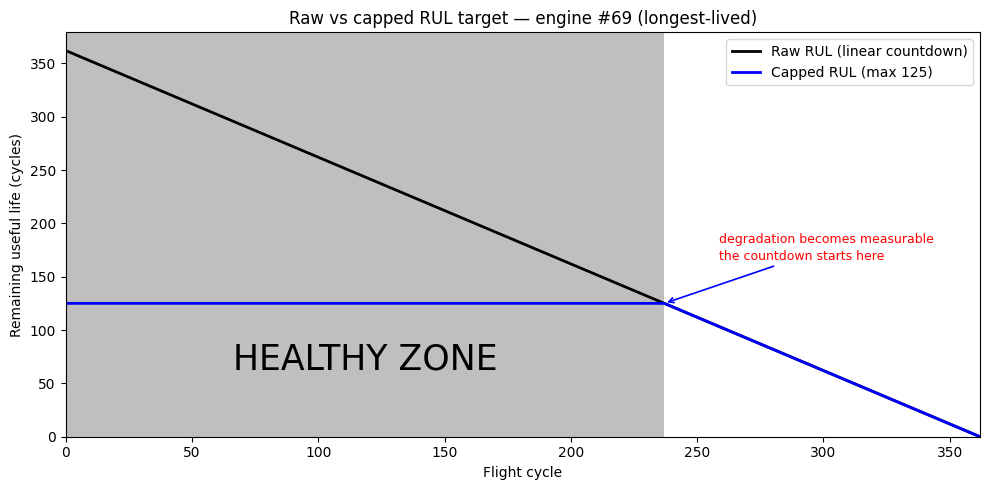

In [7]:
# We need graphs to show the results
# In order to use graphs we need another tool called matplotlib
import matplotlib.pyplot as plt

# In order to cleary visualize the healthy part we are going to use the longest-lived engine
example_unit = int(train_lifespan.idxmax())
# Stores all the data for the longest-lived engine
eng = train[train["engine"] == example_unit]

# Finding max cycle
max_cycle = int(eng["cycle"].max())

# Cycle where countdown starts
knee = max_cycle - RUL_CAP
y_top = float(eng["RUL"].max())

# Creating graph and setting size
fig, ax = plt.subplots(figsize=(10,5))

# Shade the stretch of life the capped target as healthy.
ax.axvspan(0, knee, color="gray", alpha=0.5, linewidth=0)
# Drawing the RUL line
ax.plot(eng["cycle"], eng["RUL"],
        color="black", linewidth=2, linestyle="-", label="Raw RUL (linear countdown)")
# Drawing RUL Capped line
ax.plot(eng["cycle"], eng["RUL_capped"],
        color="blue", linewidth=2, label=f"Capped RUL (max {RUL_CAP})")
# Adding text for the shaded area
ax.text(knee / 2, y_top * 0.2,
        "HEALTHY ZONE",
        ha="center", va="center", color="black", fontsize=25, linespacing=1.5)
# Adding annotations
ax.annotate("degradation becomes measurable \nthe countdown starts here",
            xy=(knee, RUL_CAP), xytext=(knee + max_cycle * 0.06, y_top * 0.46),
            color="red", fontsize=9, linespacing=1.4,
            arrowprops=dict(arrowstyle="->", color="blue", linewidth=1.2))
# Setting x-axis and y-axis limits
ax.set_xlim(0, max_cycle)
ax.set_ylim(0, y_top * 1.05)

# Adding title and labels
ax.set_title(f"Raw vs capped RUL target — engine #{example_unit} (longest-lived)")
ax.set_xlabel("Flight cycle")
ax.set_ylabel("Remaining useful life (cycles)")
# Adding box to explain what each line means
ax.legend(loc="upper right")
# Cleaning up and nicely presenting the graph
plt.tight_layout()
plt.show()

**Reading the chart**

The black line here tells us that the engine starts degrading from the first cycle, while the blue line is what we're trying to predict so the engine is classfied healthy and the line is flat, the moment it starts degrading the line would move

**Data Analysis**

In order to properly analyze the data and understand there are 3 important questions we need to answer and view.

**First Question**

How long do engines last, and how much does it vary from one engine to another?


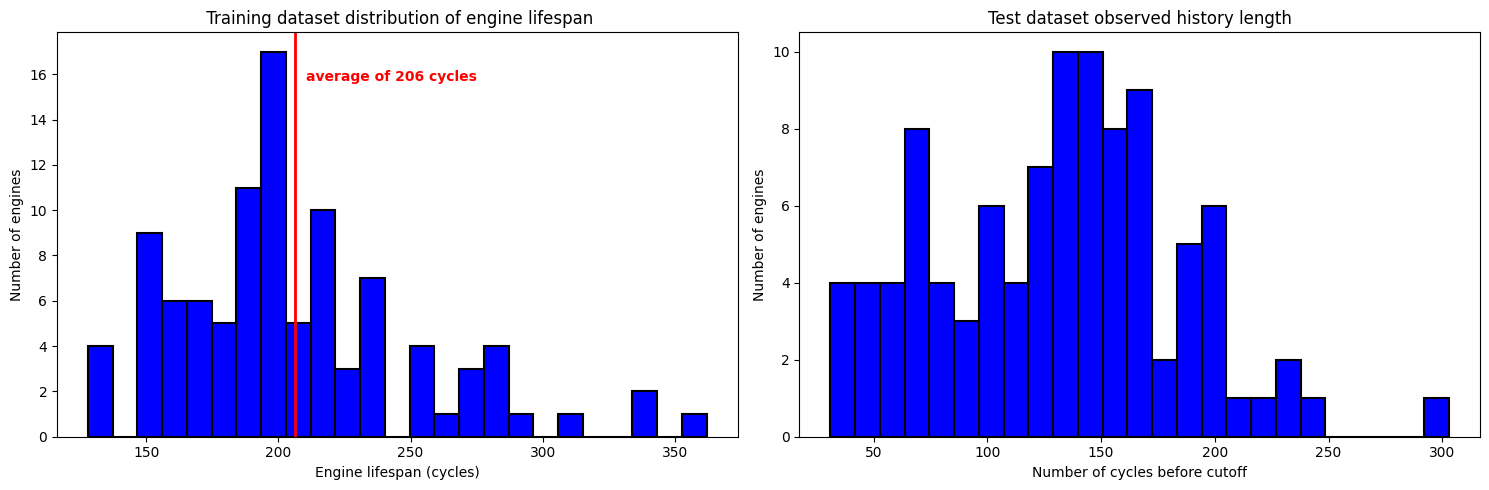

Lifetime range: 128 to 362 cycles 
the longest-lived engine lasts 2.8x as long as the shortest.


In [8]:
# Creating two plots
fig, axes = plt.subplots(1, 2, figsize=(15,5));
# Creating the first histogram, dividing the life spans into ranges of 25
axes[0].hist(train_lifespan, bins=25, color="blue", edgecolor="black", linewidth=1.5)
# Drawing a line that shows the average lifespan
axes[0].axvline(train_lifespan.mean(), color="red", linewidth=2)
axes[0].annotate(f"average of {train_lifespan.mean():.0f} cycles",
                 xy=(train_lifespan.mean(), 0), xycoords=("data", "axes fraction"),
                 xytext=(8, 0.88), textcoords=("offset points", "axes fraction"),
                 color="red", fontsize=10, fontweight="bold")
# Setting labels for the first histogram
axes[0].set_title(" Training dataset distribution of engine lifespan")
axes[0].set_xlabel("Engine lifespan (cycles)")
axes[0].set_ylabel("Number of engines")
# Creating the second histogram that show how much history we get for each engine test
axes[1].hist(test_length, bins=25, color="blue", edgecolor="black", linewidth=1.5)
axes[1].set_title("Test dataset observed history length")
axes[1].set_xlabel("Number of cycles before cutoff")
axes[1].set_ylabel("Number of engines")

plt.tight_layout()
plt.show()

# Printing life time range and how much the longest varies from the shortest-lived engine
print(f"Lifetime range: {train_lifespan.min()} to {train_lifespan.max()} cycles "
      f"\nthe longest-lived engine lasts {train_lifespan.max()/train_lifespan.min():.1f}x "
      f"as long as the shortest.")


This chart shows us that in order to predict the RUL we can't just subtract from the current cycle because there are engines that can live up to 300 cycles

**Second Question**

What does a sensor reading look like for a single engine during it's lifetime?

In order to answer that question I'll be monitoring 6 random sensors fo the first 3 engines and see how it looks, but the random sensor can't be the ones that were constant


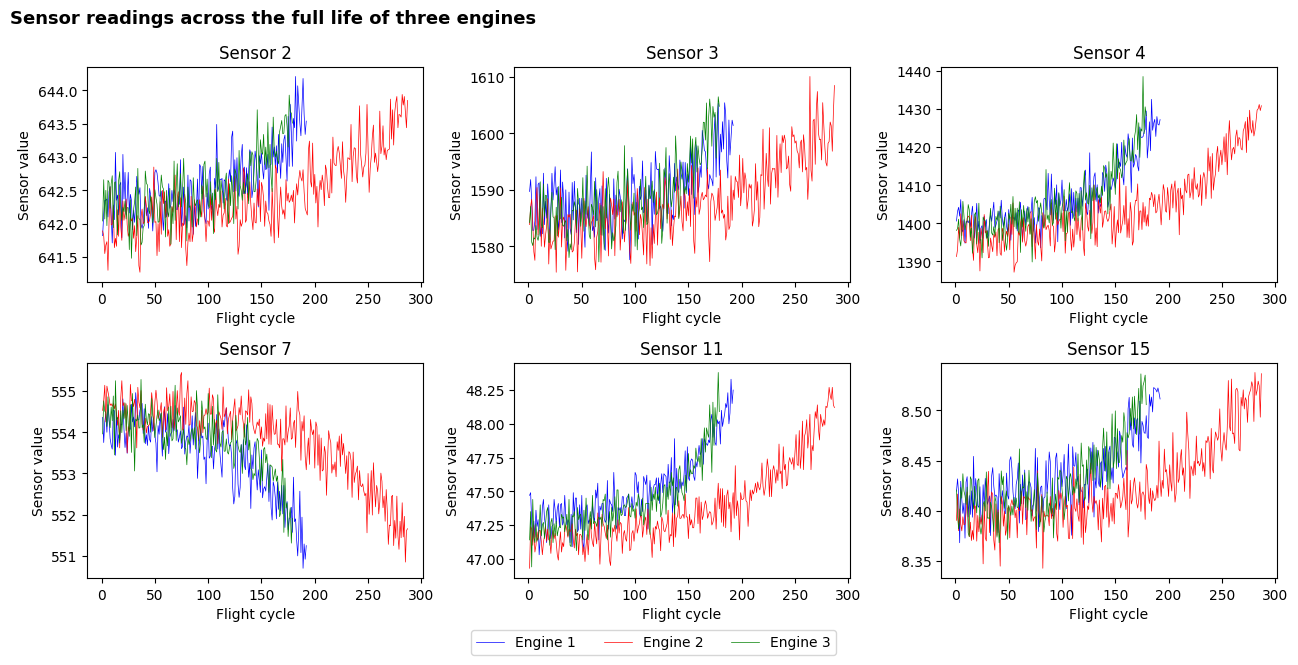

In [9]:
# Choosing non constant random sensors and the first 3 engines
informative=[c for c in columns if c not in no_variance_columns]
random_sensors=["sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_11", "sensor_15"]
random_sensors=[c for c in random_sensors if c in informative]
first_3_engines=train[train["engine"].isin(train["engine"].unique()[:3])]
sample_units=[1,2,3]
# Creating 6 plots 2x3 not sharing the x-axis
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=False)
# Defining colour in order to be able to loop through the plots easier
COLOURS=["blue","red","green"]
# Looping through plots plotting every sensor for the 3 engines and adding title and labels for each plot
for ax, sensor in zip(axes.ravel(), random_sensors):
    for colour, unit in zip(COLOURS[:3], sample_units):
        eng = train[train["engine"] == unit]
        ax.plot(eng["cycle"], eng[sensor],
                color=colour, linewidth=0.5, alpha=1, label=f"Engine {unit}")
    ax.set_title(sensor.replace("_", " ").title())
    ax.set_xlabel("Flight cycle")
    ax.set_ylabel("Sensor value")
# Creating the legend box underneath the graphs and adding a title top left
handles, labels = axes.ravel()[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Sensor readings across the full life of three engines",
             x=0.005, ha="left", fontsize=13, fontweight="bold", color='black')

plt.tight_layout()
plt.show()




**Explaining the charts**

Those charts show the readings on 6 different sensors for 3 engines, it cleary shows that the readings are noisy and they jump around a lot, but there is also a pattern you can see where towards the end the readings either climb rapidly or decrease rapidly, which shows that making a prediction is possible you just have to predict where the readings will drift.

**Question 3**

Which sensor trend consistently towards failure?

The previous charts were showing indivdual engines, now we want to know across the 100 engines which sensors rapidly drift consistently across all the engines.

In [10]:
# Imorting NumPy another tool needed for this project
import numpy as np

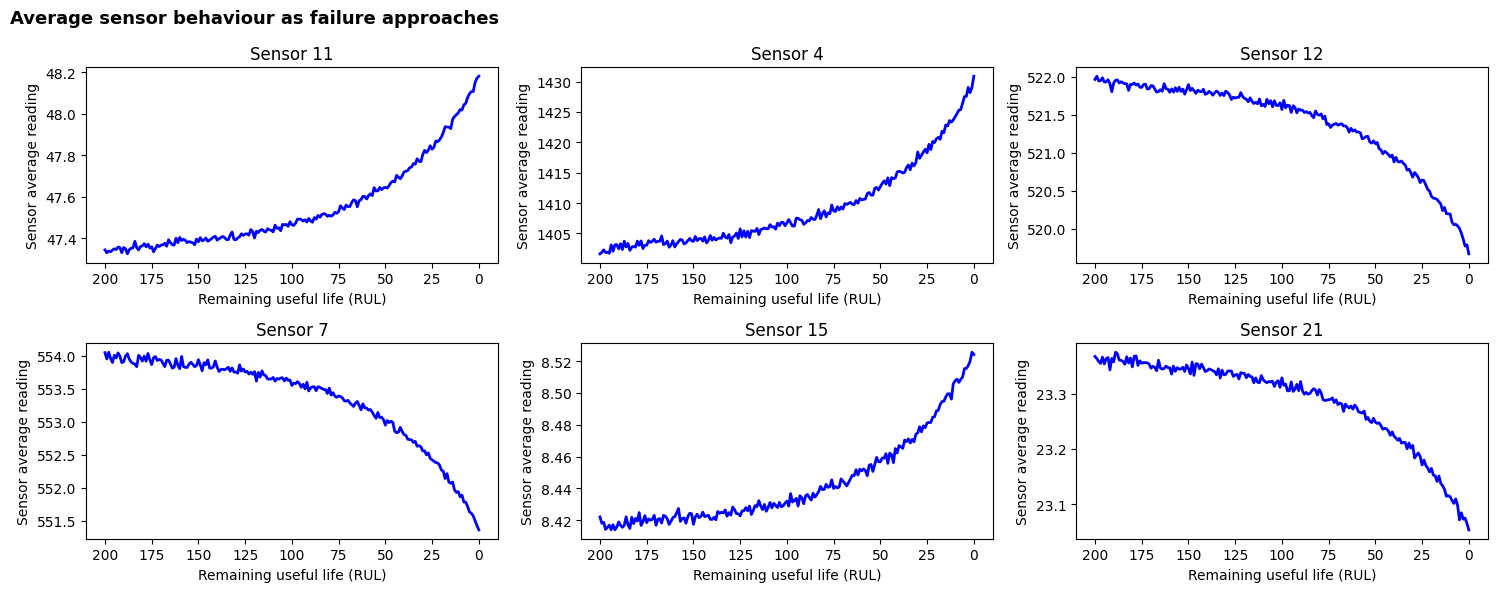

Correlation of each sensor with capped RUL (strongest first):


,Correlation with RUL
sensor_11,-0.775230
sensor_4,-0.757157
sensor_12,0.748870
sensor_7,0.733021
sensor_15,-0.720858
sensor_21,0.707334
sensor_20,0.704626
sensor_17,-0.680829
sensor_2,-0.678458
sensor_3,-0.655030


In [11]:
# Average of each sensor at each RUL value across the engines
# Where going to see the average reading when the engine has less than 200 cycles of RUL
trend = (train[train["RUL"] <= 200]
         .groupby("RUL")[informative]
         .mean()
         .sort_index(ascending=False))
# Ranking sensors by how strongly they drift as the RUL falls (correlation)
corr_with_rul = (train[informative + ["RUL_capped"]]
                 .corr()["RUL_capped"]
                 .drop("RUL_capped")
                 .sort_values(key=np.abs, ascending=False))
# Top 6 trending sensors that rapidly drift
top_trending = corr_with_rul.head(6).index.tolist()

# Creating another 6 plots for those top trending sensors
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, sensor in zip(axes.ravel(), top_trending):
    ax.plot(trend.index, trend[sensor], color="blue", linewidth=2)
    ax.invert_xaxis()   # time runs left to right: high RUL (new) to 0 (failed)
    r = corr_with_rul[sensor]
    ax.set_title(sensor.replace("_", " ").title())
    ax.set_xlabel("Remaining useful life (RUL)")
    ax.set_ylabel("Sensor average reading")
# Title
fig.suptitle("Average sensor behaviour as failure approaches",
             x=0.005, ha="left", fontsize=13, fontweight="bold", color="black")
plt.tight_layout()
plt.show()
# Print the correlation from strongest to least
print("Correlation of each sensor with capped RUL (strongest first):")
display(corr_with_rul.to_frame("Correlation with RUL").head(10))

**Exploratory Data Analysis**

We found from the last chart the core finding of the EDA, we averaged away the noise and we were able to see the trends. These sensors rise and fall steadily while the RUL is going down. Any Sensor with a +-0.7 correlations means it's a strong signal of how much life is left in that engine

**Preprocessing**

In preprocessing, we will remove the columns with zero-variance because they are no longer needed. We are going to capture a trend not just a value,that's our engineer features. We already saw from the past charts that a single reading is a poor description for the engine's health and what actually shows degradation is how unstable a sensor is across the 100 engines, we will be using an average every 5 and 20 cycles to cancel out the noise. We will also be using a per-engine baseline because engines vary slightly even when new so we will be measuring the drift relative to that engine starting point.

In [12]:
# Scaling the values of all the sensors reading so it's on one standard scale
from sklearn.preprocessing import StandardScaler

# Creating base features for sensors that actually vary
base_features=[c for c in informative]
avg_windows=(5,20)
# Creating the function engineer feeatures to sort out the values
def engineer_features(df):
    '''Add average windows and drift features, computed per engine.'''
    df = df.sort_values(["engine", "cycle"]).copy()
    grouped= df.groupby("engine")
# Creating new columns to find mean and standard deviations for every engine its a dictionary with the engine and value
    new_cols={}
# This for loop runs twice once for every window we chose and calculates mean and std for every window
    for w in avg_windows:
      rolled=grouped[base_features].rolling(window=w, min_periods=1)
      means=rolled.mean().reset_index(level=0,drop=True)
      stds=rolled.std().reset_index(level=0,drop=True).fillna(0.0)
      for col in base_features:
        new_cols[f"{col}_mean{w}"] = means[col]
        new_cols[f"{col}_std{w}"]  = stds[col]
# First reading for every sensor and its drift
    firsts = grouped[base_features] .transform("first")
#Creating a column for a drift for each sensor from its first reading
    for col in base_features:
      new_cols[f"{col}_drift"]=df[col]-firsts[col]
#Returning the combined the dataframe
    return pd.concat([df, pd.DataFrame(new_cols, index=df.index)], axis=1)



In [13]:
#Running the function on both datasets training and test
train_fe=engineer_features(train)
test_fe=engineer_features(test)
#Building a list of column names the models are going to be trained on
#Three engineered columns mean,standard deviation and drift
feature_cols = (["cycle"] + base_features +
                [col for col in train_fe.columns
                 if col.endswith(tuple([f"_mean{w}" for w in avg_windows] +
                                     [f"_std{w}" for w in avg_windows] + ["_drift"]))])
#Printing lists length for base lists and featured lists
print(f"Base columns that vary      : {len(base_features)}")
print(f"Total features after engineering: {len(feature_cols)}")

Base columns that vary      : 18
Total features after engineering: 109


In [14]:
#Training the models for every cycle of every training engine
X_train = train_fe[feature_cols] #Inputs
y_train = train_fe["RUL_capped"] #What the model is trying to predict
# The last recorded cycle from the test engines
test_last = test_fe.groupby("engine").last().reset_index()
X_test = test_last[feature_cols] #Inputs
y_test = rul_truth.loc[test_last["engine"], "RUL"].clip(upper=RUL_CAP).values #Answer key
print(f"X_train: {X_train.shape[0]} rows x {X_train.shape[1]} features")
print(f"X_test : {X_test.shape[0]} rows x {X_test.shape[1]} features")
print(f"y_test : {len(y_test)} true RUL values (capped at {RUL_CAP})")

X_train: 20631 rows x 109 features
X_test : 100 rows x 109 features
y_test : 100 true RUL values (capped at 125)


**Scaling**

Now scaling is a very important step beause these linear models need features that are on the same scale. It's only going to be fitted on the training data and then applied on the test data. This insures that the test information wont leak into the transformation because that defeats the whole idea of tring to predict those numbers. With linear regression some of the bigger values would affect the model too much if not saled effectively even though they are both important for example the cycle column goes from 1 until the max cycle which was 362. Each cycle is important for the model, without scaling some cycles could affect the model more than it's supposed to.

In [15]:
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Features scaled (fitted on training data only).")
print(f"Training mean after scaling: {X_train_scaled.mean():.5f} ")
print(f"Training std after scaling : {X_train_scaled.std():.5f} ")

Features scaled (fitted on training data only).
Training mean after scaling: -0.00000 
Training std after scaling : 0.97209 


**Building the regression models**

For this project I'll be building 4 models.

**Baseline**
It predicts the average RUL for every engine without taking into considertion any of the sensor reaings it's basically just the mean, and any model has to beat this model.

**Linear regression**

The simplest model just take RUL as a weighted sum of the sensors

**Random forest**

A collection of trees, that increases accuracy and is much more stable

**XGBoost**

Probably the strongest model out of all of them because each tree learns from the previous errors.

**Important features**

**MAE** (Mean absolute error): average error in cycles

**RMSE** (Root mean squared error): also error in cycles just squares the error first so the large errors are punished a lot more than the small errors for example being off by 50 cycles is not the same as being off by 5.

**$R^2$**: the share of variance explained for 0 being usesless and 1 being perfect

So for our models we need a lower MAE and RMSE but a higher $R^2$

I'll be adding the tools needed for each model.

I'll be creating a dictionary with the regressors it just shows model name and if it needs the scaled data so the first two models the base line and linear regression need the scaled data, but dont have any complex setting on the inside. When it comes to the Random forest and XGboost they dont need the scaled data but the have max_depth and sample leafs in order to insure they dont get too complex and we then use the random state because these models need randomness

In [16]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [17]:
#Creating the models first before training (Regression model)
regressors = {
    "Baseline (mean)": (DummyRegressor(strategy="mean"), True),
    "Linear Regression": (LinearRegression(), True),

    "Random Forest": (RandomForestRegressor(n_estimators=100, max_depth=14,
                                            min_samples_leaf=5, n_jobs=-1,
                                            random_state=RANDOM_STATE), False),
    "XGBoost": (XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6,
                             subsample=0.8, colsample_bytree=0.8, n_jobs=-1,
                             random_state=RANDOM_STATE, verbosity=0), False),
}
# Creating List and dictionaries to loop the results into them
reg_results, reg_predictions, fitted_regressors = [], {}, {}
# Looping regressor items to start training and check if model needs scaled data
for name, (model, needs_scaling) in regressors.items():
    Xtr = X_train_scaled if needs_scaling else X_train
    Xte = X_test_scaled  if needs_scaling else X_test
# Training the models and adding the results into the containers we created above
    model.fit(Xtr, y_train)
    preds = np.clip(model.predict(Xte), 0, RUL_CAP)   # RUL can't be negative

    reg_predictions[name] = preds
    fitted_regressors[name] = model
    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "R²": r2_score(y_test, preds),
    })
    print(f"{name:<20} trained")



Baseline (mean)      trained
Linear Regression    trained
Random Forest        trained
XGBoost              trained


In [18]:
# Creating a table to show the results from training
reg_df = pd.DataFrame(reg_results).set_index("Model")
print("\nRegression results on the 100 held-out test engines:")
display(reg_df.style.format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "R²": "{:.2f}"})
        .background_gradient(subset=["MAE", "RMSE"]))


Regression results on the 100 held-out test engines:


,MAE,RMSE,R²
Model,,,
Baseline (mean),34.83,41.94,-0.10
Linear Regression,13.18,16.51,0.83
Random Forest,9.46,12.46,0.90
XGBoost,9.13,12.56,0.90


**Explaining the results**

As you can see from the results the baseline had the worst results and thats expected because its just getting the average sum and it's mostly wrong with around 41 cycles.
Linear Regression. The error drops from about 42 to 16.5 cycles, and $R^2$ goes from about 0 to 0.83. That's the biggest single improvement in the table. It proves the sensors genuinely carry a signal about remaining life.
Random Forest and XGBoost. Both cut the error further, to about 12.5 cycles, with $R^2$ of 0.90. That's because tree models can capture the non-linear shape of degradation: slow for most of an engine's life, then accelerating near failure.

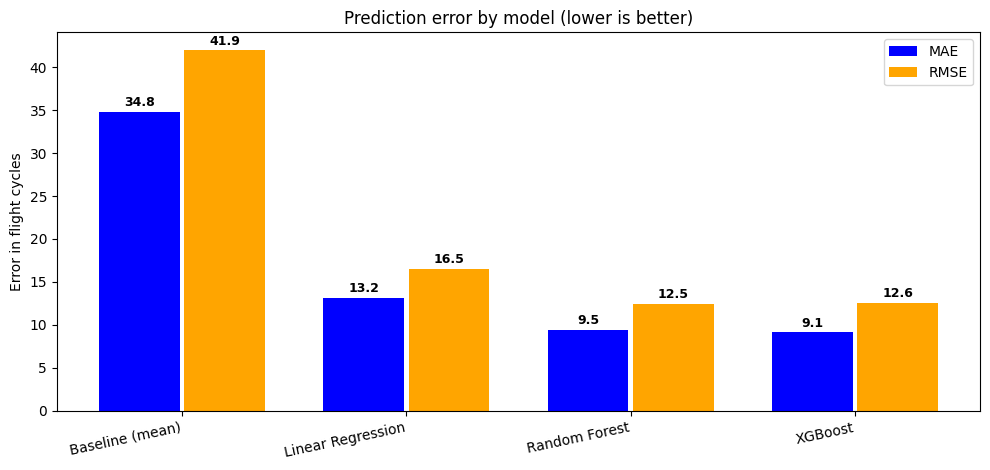

Best regression model: Random Forest (RMSE 12.46 cycles, 70.3% better than the baseline)


In [19]:
# Creating a chart to show the results

plot_df = reg_df.reset_index()
x = np.arange(len(plot_df))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 4.8))
b1 = ax.bar(x - width/2, plot_df["MAE"],  width - 0.02, label="MAE",  color="blue")
b2 = ax.bar(x + width/2, plot_df["RMSE"], width - 0.02, label="RMSE", color="orange")

for bars in (b1, b2):
    for bar in bars:
        ax.annotate(f"{bar.get_height():.1f}",
                    xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=9, color="black", fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=12, ha="right")
ax.set_title("Prediction error by model (lower is better)")
ax.set_xlabel("")
ax.set_ylabel("Error in flight cycles")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

best_reg = reg_df["RMSE"].idxmin()
improvement = (1 - reg_df.loc[best_reg, "RMSE"] / reg_df.loc["Baseline (mean)", "RMSE"]) * 100
print(f"Best regression model: {best_reg} "
      f"(RMSE {reg_df.loc[best_reg, 'RMSE']:.2f} cycles, "
      f"{improvement:.1f}% better than the baseline)")

Over-predictions (model thinks engine has MORE life than it does): 53 of 100
Under-predictions (conservative, flags engine early)              : 47 of 100
Median absolute error: 7.5 cycles


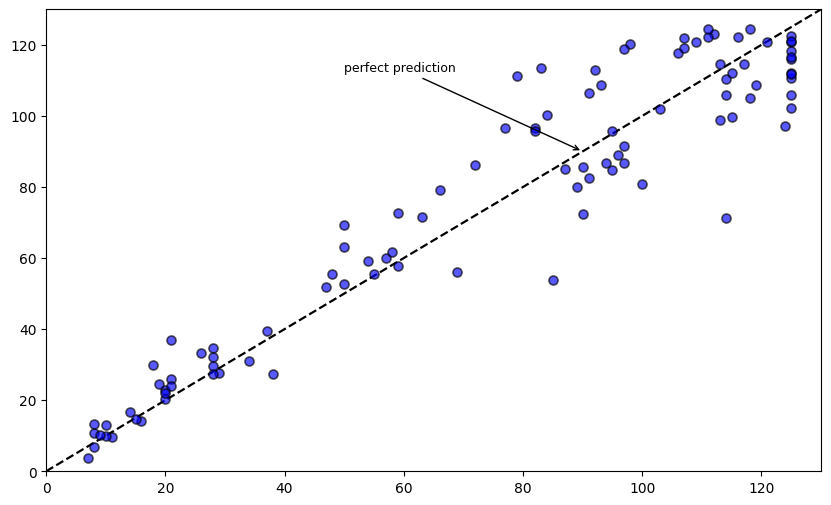

In [20]:
# Best predictions and where they land
best_preds = reg_predictions[best_reg]

fig, axes = plt.subplots(1, 1, figsize=(10, 6))
# predicted vs actual
errors=best_preds -y_test
axes.scatter(y_test, best_preds, s=42, color="blue", alpha=0.65,
                edgecolor="black", linewidth=1.2, zorder=3)
lims = [0, RUL_CAP + 5]
axes.plot(lims, lims, color="black", linestyle="--", linewidth=1.6, zorder=2)
axes.annotate("perfect prediction", xy=(RUL_CAP*0.72, RUL_CAP*0.72),
                 xytext=(RUL_CAP*0.40, RUL_CAP*0.90), color="black", fontsize=9,
                 arrowprops=dict(arrowstyle="->", color="black", linewidth=1))
axes.set_xlim(lims); axes.set_ylim(lims)
ax.set_title(f"Predicted vs actual RUL — {best_reg}")
ax.set_xlabel("Actual RUL (cycles)")
ax.set_ylabel("Predicted RUL (cycles)")




late = (errors > 0).sum()
print(f"Over-predictions (model thinks engine has MORE life than it does): {late} of {len(errors)}")
print(f"Under-predictions (conservative, flags engine early)              : {len(errors)-late} of {len(errors)}")
print(f"Median absolute error: {np.median(np.abs(errors)):.1f} cycles")

**Reading this chart.** Points sitting on the dashed line are
perfect predictions. Points above it mean the model thinks the engine is healthier than
it really is. Those are the dangerous errors in a maintenance context because they are over optimistic
prediction means an engine stays in service longer than it safely should. Points below the
line are conservative errors, which cost money in unnecessary inspections but do not cost
safety.

**Model Building** (Classification models)

The regression models were built to predict how many cycles were left for every engine. The classification models will classify each engine as healthy or not healthy using a threshold of amount of remaining cycles. The threshold I'm using for this project is 30 RUL, if an engine hits the threshold it means the engine needs maintenance soon, while anything above that is healthy. I'll be using two classification models Logisitc Regression and Random Forest classifier. I'll also be creating a chart for the confusion matrix.

**Metrics**

I'll have 4 important metrics that I Will be measuring.

**Precision:** How many engines were flagged correctly?(TP/TP+FP)

**Recall:** How many engines failed and how many did the model flag?(TP/TP+FN)

**Accuracy:** Overall how accurate was the model?(TP+TN/all)

**F1:** Mean of precision and recall(2*(precision*recall)/(precision+recall)




In [21]:
# Importing the models for classification
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc)

# Setting the threshold
FAILURE_THRESHOLD = 30

# Training the model True=1 and False=0
y_train_clf = (train_fe["RUL"] <= FAILURE_THRESHOLD).astype(int) # Comparing RUL to 30 anything less than 30 is true
y_test_clf  = (rul_truth.loc[test_last["engine"], "RUL"] <= FAILURE_THRESHOLD).astype(int).values

# Printing results of training
print(f"Training set — needs maintenance: {y_train_clf.sum():,} rows "
      f"({y_train_clf.mean():.1%}), healthy: {(1-y_train_clf).sum():,} rows")
print(f"Test set     — needs maintenance: {y_test_clf.sum()} engines "
      f"({y_test_clf.mean():.1%}), healthy: {(1-y_test_clf).sum()} engines")


Training set — needs maintenance: 3,100 rows (15.0%), healthy: 17,531 rows
Test set     — needs maintenance: 25 engines (25.0%), healthy: 75 engines


**Results**

The classes are imbalanced because in the training data set only 15% of the engines need maintenance and that makes since becuase the training data engines start healthy and run until they die so the rows where engines are supposedly healthy should be a lot more. Theoritically then a lazy model that predicts always healthy would get an 85% accuracy score thats why the class weight is going to be important. Class weight makes sure that the mistakes are punished heavily for example in this training dataset, there are over 17000 rows that are healthy while on 3100 rows that are unhealthy. With imbalance they are all treated equally but the 3100 rows are more important because its what the model is trying to predict so if you punish these mistakes the model wont be lazy anymore.

In [22]:
# Creating classifier models
classifiers = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced",
                                               random_state=RANDOM_STATE), True),
    "Random Forest": (RandomForestClassifier(n_estimators=100, max_depth=12,
                                             min_samples_leaf=5, class_weight="balanced",
                                             n_jobs=-1, random_state=RANDOM_STATE), False),
}

In [23]:
# Same with the regression models creating containers for the results
clf_results, clf_probabilities, fitted_classifiers = [], {}, {}
# If model needs scaling or not
for name, (model, needs_scaling) in classifiers.items():
    Xtr = X_train_scaled if needs_scaling else X_train
    Xte = X_test_scaled  if needs_scaling else X_test
# Training the model and getting predictions
    model.fit(Xtr, y_train_clf)
    preds = model.predict(Xte)
    probs = model.predict_proba(Xte)[:, 1]
    clf_probabilities[name] = (preds, probs)
    fitted_classifiers[name] = model
    clf_results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test_clf, preds),
        "Precision": precision_score(y_test_clf, preds, zero_division=0),
        "Recall":    recall_score(y_test_clf, preds, zero_division=0),
        "F1":        f1_score(y_test_clf, preds, zero_division=0),
    })
# Creating table
clf_df = pd.DataFrame(clf_results).set_index("Model")
print("Classification results on the 100 test engines:")
display(clf_df.style.format("{:.3f}").background_gradient(cmap="Blues"))

# Best classifier
best_clf = clf_df.sort_values(["Recall"], ascending=False).index[0]
print(f"\nBest model by recall (fewest missed failures):{best_clf}")
print(f"\nDetailed report: {best_clf}:")
print(classification_report(y_test_clf, clf_probabilities[best_clf][0],
                            target_names=["Healthy", "Needs maintenance"],
                            zero_division=0))


Classification results on the 100 test engines:


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.990,0.962,1.000,0.980
Random Forest,0.950,0.917,0.880,0.898



Best model by recall (fewest missed failures):Logistic Regression

Detailed report: Logistic Regression:
                   precision    recall  f1-score   support

          Healthy       1.00      0.99      0.99        75
Needs maintenance       0.96      1.00      0.98        25

         accuracy                           0.99       100
        macro avg       0.98      0.99      0.99       100
     weighted avg       0.99      0.99      0.99       100



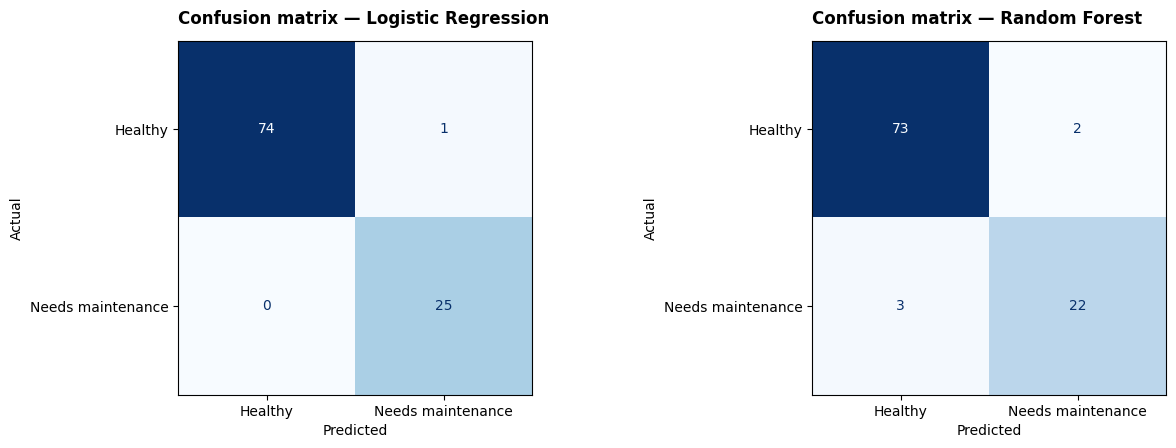

In [24]:
# Confusion matrix

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

for ax,name in zip(axes[0:],classifiers.keys()):
    preds = clf_probabilities[name][0]
    cm = confusion_matrix(y_test_clf, preds)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Healthy", "Needs maintenance"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Confusion matrix — {name}", loc="left", fontweight="bold", pad=12)
    ax.grid(False)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

**Confusion Matrix**

Top-left: is true positive which means healthy engines were correctly predicted as healthy

Top-right: is false positive which means healthy engines were predicted as needing maintenance

Bottom-left: is False negative which means engines that were needing maintenance but didnt get flagged

Bottom-right: is fals epositive and the most important cell where engines that needed maintenance were flagged


In [25]:
# Conclusion
print("AIRCRAFT PREDICTIVE MAINTENANCE FINAL RESULTS (NASA C-MAPSS, FD001)")
print(f"\nDataset: {train['engine'].nunique()} training engines "
      f"({len(train):,} cycles), {test['engine'].nunique()} test engines")
print(f"Features: {len(feature_cols)} (from {len(base_features)} varying columns)")
print(f"RUL capped at {RUL_CAP} cycles")
print("\nModel 1: RUL regression model (error in flight cycles)")
print(reg_df.to_string(float_format=lambda v: f"{v:8.3f}"))
print(f"\nBest: {best_reg} — RMSE {reg_df.loc[best_reg,'RMSE']:.2f} cycles, "
      f"MAE {reg_df.loc[best_reg,'MAE']:.2f} cycles, R² {reg_df.loc[best_reg,'R²']:.3f}")
print("\nModel 2: Failure classification model (healthy/needs maintenance)")
print(clf_df.to_string(float_format=lambda v: f"{v:8.3f}"))
print(f"\nBest: {best_clf}")

AIRCRAFT PREDICTIVE MAINTENANCE FINAL RESULTS (NASA C-MAPSS, FD001)

Dataset: 100 training engines (20,631 cycles), 100 test engines
Features: 109 (from 18 varying columns)
RUL capped at 125 cycles

Model 1: RUL regression model (error in flight cycles)
                       MAE     RMSE       R²
Model                                       
Baseline (mean)     34.830   41.942   -0.095
Linear Regression   13.178   16.512    0.830
Random Forest        9.459   12.463    0.903
XGBoost              9.125   12.559    0.902

Best: Random Forest — RMSE 12.46 cycles, MAE 9.46 cycles, R² 0.903

Model 2: Failure classification model (healthy/needs maintenance)
                     Accuracy  Precision   Recall       F1
Model                                                     
Logistic Regression     0.990      0.962    1.000    0.980
Random Forest           0.950      0.917    0.880    0.898

Best: Logistic Regression
